# Pandas

:::{admonition} Learning outcomes
:class: tip
After this tutorial, you can

- load, clean and combine tabular data with `pandas`,
- sort, filter, group and aggregate data, and
- analyse and plot time series.
:::

:::{dropdown} YouTube Video
:::{iframe} https://www.youtube.com/embed/rI27Xm_ny10
:width: 100%
Video not loading? Click [here](https://www.youtube.com/watch?v=rI27Xm_ny10).
:::

:::{note}
This material is mostly adapted from the following resources:
- [Earth and Environmental Data Science: Pandas](https://earth-env-data-science.github.io/lectures/pandas/pandas_intro.html)
- [Python Programming for Data Science: Pandas](https://www.tomasbeuzen.com/python-programming-for-data-science/chapters/chapter7-pandas.html)
:::

<img src="https://pandas.pydata.org/static/img/pandas.svg" width="300px" />

[Pandas](http://pandas.pydata.org/) is an open-source library providing Excel-like tables in Python.
It offers functionality for efficiently reading, writing, and processing data such as sorting, filtering, aggregating, and visualizing. Moreover, it provides tools for handling missing data and time series data.

<img src="https://media.geeksforgeeks.org/wp-content/cdn-uploads/creating_dataframe1.png" width="720px" />

:::{note}
Documentation for this package is available at https://pandas.pydata.org/docs/.
:::

:::{note}
If you have not yet set up Python on your computer, you can execute this tutorial in your browser via [Google Colab](https://colab.research.google.com/). Download the `.ipynb` file using the download button on the top right corner and import it in [Google Colab](https://colab.research.google.com/).

Then install `pandas` and `numpy` by executing the following command in a Jupyter cell at the top of the notebook.

```sh
!pip install pandas numpy
```
:::

In [64]:
import pandas as pd
import numpy as np

## The `Series`

A Series represents a one-dimensional array of data. The main difference between a Series and a numpy array is that a Series has an **index**. The index contains the labels that we use to access the data. It is actually quite similar to a Python dictionary, where each value is associated with a key.

There are many ways to [create a Series](https://pandas.pydata.org/pandas-docs/stable/dsintro.html#series), but the core constructor is [`pd.Series()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.html) which can process a dictionary to create a Series.

:::{note}
The data used below is from Wikipedia's [List of power stations in Germany](https://en.wikipedia.org/wiki/List_of_power_stations_in_Germany#Nuclear).
:::

In [65]:
dictionary = {
    "Neckarwestheim": 1269,
    "Isar 2": 1365,
    "Emsland": 1290,
}
s = pd.Series(dictionary)
s

Neckarwestheim    1269
Isar 2            1365
Emsland           1290
dtype: int64

In [66]:
dictionary

{'Neckarwestheim': 1269, 'Isar 2': 1365, 'Emsland': 1290}

Arithmetic operations and most `numpy` functions can be applied to `pd.Series`.
An important point is that the Series keep their index during such operations.

In [67]:
np.log(s) / s**0.5

Neckarwestheim    0.200600
Isar 2            0.195391
Emsland           0.199418
dtype: float64

We can access the underlying index object if we need to:

In [68]:
s.index

Index(['Neckarwestheim', 'Isar 2', 'Emsland'], dtype='str')

We can get values back out using the index via the `.loc` attribute

In [69]:
s.loc["Isar 2"]

np.int64(1365)

Or by raw position using `.iloc`

In [70]:
s.iloc[2]

np.int64(1290)

We can pass a list or array to loc to get multiple rows back:

In [71]:
s.loc[["Neckarwestheim", "Emsland"]]

Neckarwestheim    1269
Emsland           1290
dtype: int64

And we can even use so-called *slicing* notation (`:`) to get ranges of rows:

In [72]:
s.loc["Neckarwestheim":"Emsland"]

Neckarwestheim    1269
Isar 2            1365
Emsland           1290
dtype: int64

In [73]:
s.iloc[:2]

Neckarwestheim    1269
Isar 2            1365
dtype: int64

If we need to, we can always get the raw data back out as well

In [74]:
type(s.values)  # a numpy array

numpy.ndarray

## The `DataFrame`

There is a lot more to a `pandas.Series`, but they are limited to a single **column**. A more broadly useful Pandas data structure is the **DataFrame**. `pandas.DataFrame` is a collection of series that share the same index. It's a lot like a table in a spreadsheet.

The core constructor is `pd.DataFrame()`, which can be used like this using a dictionary of lists:

In [75]:
data = {
    "capacity": [1269, 1365, 1290],  # MW
    "type": ["PWR", "PWR", "PWR"],
    "start_year": [1989, 1988, 1988],
    "end_year": [np.nan, np.nan, np.nan],
}

In [76]:
df = pd.DataFrame(data, index=["Neckarwestheim", "Isar 2", "Emsland"])
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,NaN
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,NaN


We can also switch columns and rows very easily using the `.T` (transpose) attribute:

In [77]:
df.T

,Neckarwestheim,Isar 2,Emsland
capacity,1269,1365,1290
type,PWR,PWR,PWR
start_year,1989,1988,1988
end_year,NaN,NaN,NaN


A wide range of statistical functions are available on both Series and DataFrames.

In [78]:
df.min()

capacity      1269
type           PWR
start_year    1988
end_year       NaN
dtype: object

In [79]:
df.mean(numeric_only=True)

capacity      1308.000000
start_year    1988.333333
end_year              NaN
dtype: float64

In [80]:
df.describe()

,capacity,start_year,end_year
count,3.000000,3.000000,0.0
mean,1308.000000,1988.333333,NaN
std,50.467812,0.577350,NaN
min,1269.000000,1988.000000,NaN
25%,1279.500000,1988.000000,NaN
50%,1290.000000,1988.000000,NaN
75%,1327.500000,1988.500000,NaN
max,1365.000000,1989.000000,NaN


We can get a single column as a Series using python's getitem syntax on the DataFrame object.

In [81]:
df["capacity"]

Neckarwestheim    1269
Isar 2            1365
Emsland           1290
Name: capacity, dtype: int64

...or using attribute syntax.

In [82]:
df.end_year

Neckarwestheim   NaN
Isar 2           NaN
Emsland          NaN
Name: end_year, dtype: float64

Indexing works very similar to series

In [83]:
df.loc["Emsland"]

capacity      1290
type           PWR
start_year    1988
end_year       NaN
Name: Emsland, dtype: object

In [84]:
df.iloc[2]

capacity      1290
type           PWR
start_year    1988
end_year       NaN
Name: Emsland, dtype: object

But we can also specify the column(s) and row(s) we want to access

In [85]:
df.loc["Emsland", "start_year"]

np.int64(1988)

In [86]:
df.loc[["Emsland", "Neckarwestheim"], ["start_year", "end_year"]]

,start_year,end_year
Emsland,1988,NaN
Neckarwestheim,1989,NaN


Mathematical operations work as well, either on the whole DataFrame or on specific columns, the result of which can be assigned to a new column:

In [87]:
df.capacity * 0.8

Neckarwestheim    1015.2
Isar 2            1092.0
Emsland           1032.0
Name: capacity, dtype: float64

In [88]:
df["reduced_capacity"] = df.capacity * 0.8
df

,capacity,type,start_year,end_year,reduced_capacity
Neckarwestheim,1269,PWR,1989,NaN,1015.2
Isar 2,1365,PWR,1988,NaN,1092.0
Emsland,1290,PWR,1988,NaN,1032.0


## Cleaning Data

We can also **remove** columns or rows from a DataFrame:

In [89]:
df.drop("reduced_capacity", axis="columns")
df

,capacity,type,start_year,end_year,reduced_capacity
Neckarwestheim,1269,PWR,1989,NaN,1015.2
Isar 2,1365,PWR,1988,NaN,1092.0
Emsland,1290,PWR,1988,NaN,1032.0


We can update the variable `df` by either overwriting `df` or passing an `inplace` keyword:

In [90]:
df = df.drop("reduced_capacity", axis="columns")

In [91]:
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,NaN
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,NaN


We can also **drop columns** with only NaN values

In [92]:
df.dropna(axis=1, how="all")

,capacity,type,start_year
Neckarwestheim,1269,PWR,1989
Isar 2,1365,PWR,1988
Emsland,1290,PWR,1988


Or fill it up with default **fallback** data:

In [93]:
df.fillna(2023)
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,NaN
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,NaN


Say, we already have one value for `end_year` and want to fill up the **missing data**. We can use forward fill (`ffill`) or backward fill (`bfill`):

In [94]:
df.loc["Emsland", "end_year"] = 2023
df.loc["Neckarwestheim", "end_year"] = 2023
df

,capacity,type,start_year,end_year
Neckarwestheim,1269,PWR,1989,2023.0
Isar 2,1365,PWR,1988,NaN
Emsland,1290,PWR,1988,2023.0


In [95]:
df["end_year"] = df["end_year"].ffill()
df
df["x"] = np.nan
df["y"] = np.nan
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,NaN
Isar 2,1365,PWR,1988,2023.0,NaN,NaN
Emsland,1290,PWR,1988,2023.0,NaN,NaN


Sometimes it can be useful to **rename** columns:

In [96]:
df.rename(columns=dict(x="lon", y="lat"))

,capacity,type,start_year,end_year,lon,lat
Neckarwestheim,1269,PWR,1989,2023.0,NaN,NaN
Isar 2,1365,PWR,1988,2023.0,NaN,NaN
Emsland,1290,PWR,1988,2023.0,NaN,NaN


Sometimes it can be useful to **replace** values:

In [97]:
df.replace({"PWR": "Pressurized water reactor"})

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,Pressurized water reactor,1989,2023.0,NaN,NaN
Isar 2,1365,Pressurized water reactor,1988,2023.0,NaN,NaN
Emsland,1290,Pressurized water reactor,1988,2023.0,NaN,NaN


In [98]:
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,NaN
Isar 2,1365,PWR,1988,2023.0,NaN,NaN
Emsland,1290,PWR,1988,2023.0,NaN,NaN


In many cases, we want to **modify** values in a dataframe based on some rule. To modify values, we need to use `.loc` or `.iloc`. It can be used to set a specific value or a set of values based on their index and column labels:

In [99]:
df.loc["Isar 2", "start_year"] = 2000
df.loc["Emsland", "capacity"] += 10
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,NaN
Isar 2,1365,PWR,2000,2023.0,NaN,NaN
Emsland,1300,PWR,1988,2023.0,NaN,NaN


It can also be a whole column:

In [100]:
plants = ["Neckarwestheim", "Isar 2", "Emsland"]
df.loc[plants, "y"] = [49.04, 48.61, 52.47]
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,49.04
Isar 2,1365,PWR,2000,2023.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47


## Combining Datasets

Pandas supports a wide range of methods for merging different datasets. These are described extensively in the [documentation](https://pandas.pydata.org/pandas-docs/stable/merging.html). Here we just give a few examples.

In [101]:
data = {
    "capacity": [1288, 1360, 1326],  # MW
    "type": ["BWR", "PWR", "PWR"],
    "start_year": [1985, 1985, 1986],
    "end_year": [2021, 2021, 2021],
    "x": [10.40, 9.41, 9.35],
    "y": [48.51, 52.03, 53.85],
}
df2 = pd.DataFrame(data, index=["Gundremmingen", "Grohnde", "Brokdorf"])
df2

,capacity,type,start_year,end_year,x,y
Gundremmingen,1288,BWR,1985,2021,10.40,48.51
Grohnde,1360,PWR,1985,2021,9.41,52.03
Brokdorf,1326,PWR,1986,2021,9.35,53.85


We can now add this additional data to the `df` object

In [102]:
df = pd.concat([df, df2])
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,49.04
Isar 2,1365,PWR,2000,2023.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


## Sorting & Filtering Data

We can also **sort** the entries in dataframes, e.g. alphabetically by index or numerically by column values

In [103]:
df.sort_index()

,capacity,type,start_year,end_year,x,y
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Isar 2,1365,PWR,2000,2023.0,NaN,48.61
Neckarwestheim,1269,PWR,1989,2023.0,NaN,49.04


In [104]:
df.sort_values(by="end_year", ascending=False)

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,49.04
Isar 2,1365,PWR,2000,2023.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


We can also **filter** a DataFrame using a boolean series obtained from a condition. This is very useful to build subsets of the DataFrame.

In [105]:
df.capacity > 1300

Neckarwestheim    False
Isar 2             True
Emsland           False
Gundremmingen     False
Grohnde            True
Brokdorf           True
Name: capacity, dtype: bool

In [106]:
df[df.capacity > 1300]

,capacity,type,start_year,end_year,x,y
Isar 2,1365,PWR,2000,2023.0,NaN,48.61
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


We can also combine multiple conditions, but we need to wrap the conditions with brackets!

In [107]:
df[(df.capacity > 1300) & (df.start_year >= 1988)]

,capacity,type,start_year,end_year,x,y
Isar 2,1365,PWR,2000,2023.0,NaN,48.61


Or we make [SQL-like](https://en.wikipedia.org/wiki/SQL) queries:

In [108]:
df.query("start_year == 1988")

,capacity,type,start_year,end_year,x,y
Emsland,1300,PWR,1988,2023.0,NaN,52.47


In [109]:
threshold = 1300
df.query("start_year == 1988 and capacity > @threshold")

,capacity,type,start_year,end_year,x,y


In [110]:
df

,capacity,type,start_year,end_year,x,y
Neckarwestheim,1269,PWR,1989,2023.0,NaN,49.04
Isar 2,1365,PWR,2000,2023.0,NaN,48.61
Emsland,1300,PWR,1988,2023.0,NaN,52.47
Gundremmingen,1288,BWR,1985,2021.0,10.40,48.51
Grohnde,1360,PWR,1985,2021.0,9.41,52.03
Brokdorf,1326,PWR,1986,2021.0,9.35,53.85


## Applying Functions

Sometimes it can be useful to **apply** a function to all values of a column/row. For instance, we might be interested in normalised capacities relative to the largest nuclear power plant:

In [111]:
def normalise(s):
    return s / df.capacity.max()


df.capacity.apply(normalise)

Neckarwestheim    0.929670
Isar 2            1.000000
Emsland           0.952381
Gundremmingen     0.943590
Grohnde           0.996337
Brokdorf          0.971429
Name: capacity, dtype: float64

For simple functions, there's often an easier alternative:

In [112]:
df.capacity / df.capacity.max()

Neckarwestheim    0.929670
Isar 2            1.000000
Emsland           0.952381
Gundremmingen     0.943590
Grohnde           0.996337
Brokdorf          0.971429
Name: capacity, dtype: float64

But the `.apply()` function often gives you more flexibility.

## Plotting

DataFrames have all kinds of [useful plotting](https://pandas.pydata.org/pandas-docs/stable/visualization.html) built in.

:::{note}
Note, that we do not even have to import `matplotlib` for this. It is used under the hood by `pandas` to create the plots.
:::

<Axes: xlabel='start_year', ylabel='capacity'>

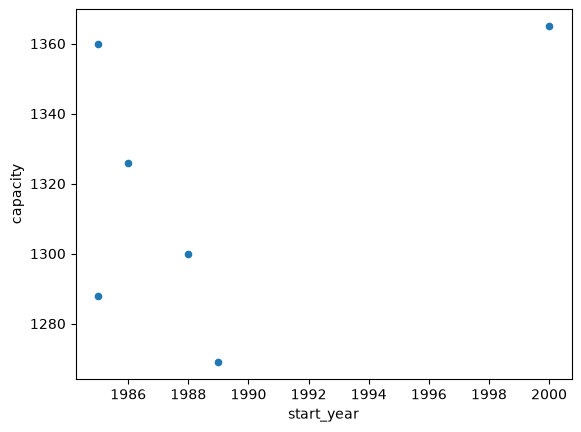

In [113]:
df.plot(kind="scatter", x="start_year", y="capacity")

Text(0.5, 0, 'Capacity (MW)')

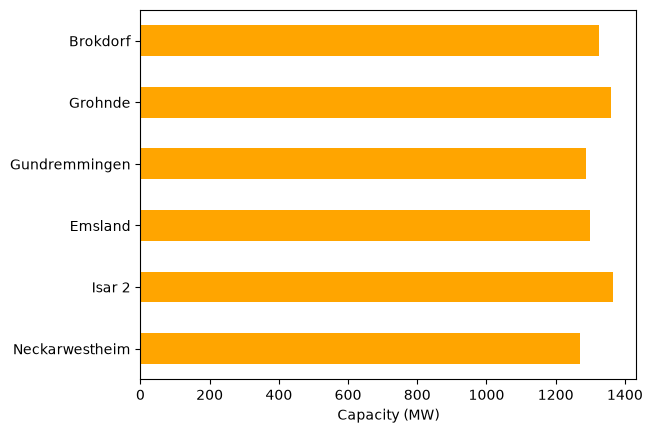

In [114]:
df.capacity.plot.barh(color="orange")
import matplotlib.pyplot as plt

plt.xlabel("Capacity (MW)")

## Time Indexes

Indexes are very powerful. They are a big part of why Pandas is so useful. There are different indices for different types of data. Time Indexes are especially great when handling time-dependent data.

In [115]:
time = pd.date_range(start="2021-01-01", end="2023-01-01", freq="D")
time.day_of_year

Index([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,
       ...
       357, 358, 359, 360, 361, 362, 363, 364, 365,   1],
      dtype='int32', length=731)

In [116]:
values = np.sin(2 * np.pi * time.day_of_year / 365)
values

Index([ 0.017213356155834685,   0.03442161162274574,  0.051619667223253764,
         0.06880242680231986,   0.08596479873744647,   0.10310169744743485,
          0.1202080448993527,   0.13727877211326478,   0.15430882066428117,
          0.1712931441814776,
       ...
        -0.13727877211326517,  -0.12020804489935275,  -0.10310169744743544,
         -0.0859647987374467,  -0.06880242680232064,  -0.05161966722325418,
       -0.034421611622745804,  -0.01721335615583528, 6.432490598706546e-16,
        0.017213356155834685],
      dtype='float64', length=731)

In [117]:
values = np.sin(2 * np.pi * time.day_of_year / 365)
ts = pd.Series(values, index=time)
ts

2021-01-01    1.721336e-02
2021-01-02    3.442161e-02
2021-01-03    5.161967e-02
2021-01-04    6.880243e-02
2021-01-05    8.596480e-02
                  ...     
2022-12-28   -5.161967e-02
2022-12-29   -3.442161e-02
2022-12-30   -1.721336e-02
2022-12-31    6.432491e-16
2023-01-01    1.721336e-02
Freq: D, Length: 731, dtype: float64

<Axes: >

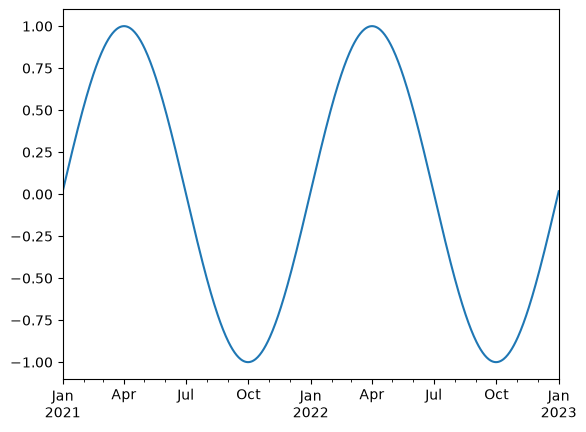

In [118]:
ts.plot()

We can use Python's _slicing_ notation inside `.loc` to select a date range.

<Axes: >

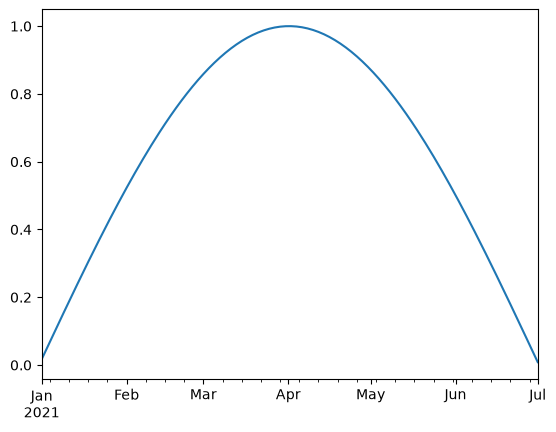

In [119]:
ts.loc["2021-01-01":"2021-07-01"].plot()

<Axes: >

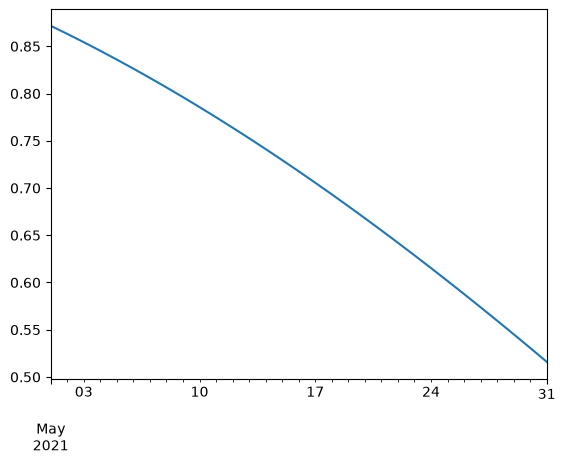

In [120]:
ts.loc["2021-05"].plot()

The `pd.DatetimeIndex` object has lots of useful attributes

In [121]:
ts.index.month

Index([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       ...
       12, 12, 12, 12, 12, 12, 12, 12, 12,  1],
      dtype='int32', length=731)

In [122]:
ts.index.day_of_week

Index([4, 5, 6, 0, 1, 2, 3, 4, 5, 6,
       ...
       4, 5, 6, 0, 1, 2, 3, 4, 5, 6],
      dtype='int32', length=731)

Another common operation is to **change the resolution** of a dataset by resampling in time. Pandas exposes this through the `.resample()` function. The resample periods are specified using pandas [offset alias](https://pandas.pydata.org/docs/user_guide/timeseries.html#offset-aliases) syntax.

Below, we first **upsample** to 12-hourly values and interpolate, then **resample** to monthly means.

In [123]:
ts.resample("12h").mean().interpolate()

2021-01-01 00:00:00    1.721336e-02
2021-01-01 12:00:00    2.581748e-02
2021-01-02 00:00:00    3.442161e-02
2021-01-02 12:00:00    4.302064e-02
2021-01-03 00:00:00    5.161967e-02
                           ...     
2022-12-30 00:00:00   -1.721336e-02
2022-12-30 12:00:00   -8.606678e-03
2022-12-31 00:00:00    6.432491e-16
2022-12-31 12:00:00    8.606678e-03
2023-01-01 00:00:00    1.721336e-02
Freq: 12h, Length: 1461, dtype: float64

<Axes: >

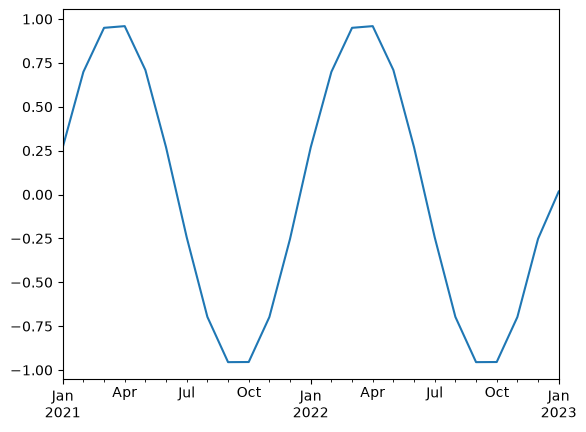

In [124]:
ts.resample("ME").mean().plot()

## Reading and Writing Files

To **read** data into pandas, we can use for instance the [`pd.read_csv()`](https://pandas.pydata.org/pandas-docs/stable/generated/pandas.read_csv.html) function. This function is quite powerful and complex with many different settings. You can use it to extract data from almost any text file.

The `pd.read_csv()` function can take a path to a local file as an input, or even a hyperlink to an online text file.

Let's import a slightly larger dataset about the power plant fleet in Europe:

In [125]:
fn = "https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv"

In [126]:
df = pd.read_csv(fn, index_col=0)
df.iloc[:5, :10]

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)>

In [ ]:
df.info()

In [ ]:
df.describe()

Sometimes, we also want to **store** a DataFrame for later use. There are many different file formats tabular data can be stored in,  including HTML, JSON, Excel, Parquet, Feather, etc. Here, let's say we want to store the DataFrame as CSV (comma-separated values) file under the name "tmp.csv".

In [ ]:
df.to_csv("tmp.csv")

In [ ]:
df

## Grouping and Aggregation

Both `Series` and `DataFrame` objects have a `groupby` method, which allows you to **group and aggregate** the data based on the values of one or more columns.

It accepts a variety of arguments, but the simplest way to think about it is that you pass another series, whose unique values are used to split the original object into different groups.

Here's an example which retrieves the total generation capacity per country.

In [ ]:
grouped = df.groupby("Country").Capacity.sum()
grouped.sort_values(ascending=False).head(10)

Such **chaining** of multiple operations is very common with pandas.

Let's break apart this operation a bit. The workflow with `groupby` can be divided into three general steps:

1. **Split**: Partition the data into different groups based on some criterion.
1. **Apply**: Do some calculation (e.g. aggregation or transformation) within each group.
1. **Combine**: Put the results back together into a single object.

<img src="https://miro.medium.com/max/1840/1*JbF6nhrQsn4f-TaSF6IR9g.png" width="720px" />

Grouping is not only possible on a single column, but also on multiple columns. For instance,
we might want to group the capacities by country **and** fuel type. To achieve this, we pass a list of column names to the `groupby` method.

In [ ]:
capacities = df.groupby(["Country", "Fueltype"]).Capacity.sum()
capacities

By grouping by multiple attributes, our index becomes a `pd.MultiIndex` (a hierarchical index with multiple *levels*).

In [ ]:
capacities.index[:5]

In [ ]:
type(capacities.index)

In [ ]:
df.nsmallest(10, "Capacity")

We can use the `.unstack` function to reshape the multi-indexed `pd.Series` into a `pd.DataFrame` which has the second index level as columns. 

In [ ]:
capacities.unstack().fillna(0.0).T.round(1)

**In summary,** the typical workflow with pandas consists of reading data from files, inspecting and cleaning the data, performing analysis through transformation and aggregation, visualizing the results, and storing the processed data for later use.

## Exercises

### Power Plants Data

In this exercise, we will use the [powerplants.csv](https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv) dataset from the [powerplantmatching](https://github.com/PyPSA/powerplantmatching) project. This dataset contains information about various power plants, including their names, countries, fuel types, capacities, and more.

URL: `https://raw.githubusercontent.com/PyPSA/powerplantmatching/master/powerplants.csv`

**Task 1:** Load the dataset into a pandas DataFrame.

In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# start with the notebook's working directory
notebook_path = Path.cwd()

# define project folder path
project_path = notebook_path.parent

# define data folder path
data_path = project_path / "data"

# define the file path for the powerplants CSV file
powerplants_file = data_path / "powerplants.txt"

# read the csv data
df = pd.read_csv(powerplants_file, index_col=0)

display(df.head())

,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh,EIC,projectID
id,,,,,,,,,,,,,,,,,,
0,Obervermuntwerk Maschine Turbine,Hydro,Pumped Storage,Store,Austria,380.0,0.75,1943.0,2018.0,NaN,46.93529,10.05995,71.573684,35.630769,291.00,27198.0,set(),"{'MASTR': {'MASTR-SEE984944424651', 'MASTR-SEE..."
1,Cruachan,Hydro,Pumped Storage,Store,United Kingdom,440.0,NaN,1965.0,1965.0,NaN,56.40640,-5.11300,15.909091,11.300000,46.00,9680.0,{'48WSTN00000CRUAC'},"{'GEM': {'G100000603737'}, 'EESI': {'EESI-1521..."
2,Limmern,Hydro,Pumped Storage,Store,Switzerland,1352.0,NaN,1964.0,2016.0,NaN,46.86255,8.99975,27.997365,25.000000,329.00,68000.0,{'12W-0000000018-B'},"{'GEM': {'G100000603536', 'G100000603559'}, 'E..."
3,Porabka Zar,Hydro,Pumped Storage,Store,Poland,552.0,NaN,1953.0,1998.0,NaN,49.78030,19.21160,3.629764,28.910000,440.00,4000.0,{'19W000000000247X'},"{'GEM': {'G100000603214'}, 'EESI': {'EESI-1471..."
4,Roncovalgrande,Hydro,Pumped Storage,Store,Italy,1000.0,NaN,1970.0,NaN,NaN,46.06940,8.73240,17.421260,10.000000,736.25,8000.0,"{'26W-S03RNCVRONCH', '26WIMPI-S03RNCVS'}","{'GEM': {'G100000602249'}, 'EESI': {'EESI-1490..."


**Task 2:** Run the function `.describe()` on the DataFrame.

In [136]:
df.describe()

,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh
count,302263.000000,511.000000,297677.000000,2594.000000,8441.000000,302301.000000,302301.000000,6364.000000,1777.000000,2041.000000,7.160000e+03
mean,5.358940,0.491690,2015.054344,1986.755204,2022.834735,50.674953,9.837007,215.328174,206.617056,186.178177,1.353912e+04
std,58.138263,0.176997,11.204233,25.485336,4.574041,2.784949,3.662447,808.737070,991.347641,250.734724,1.228374e+05
min,0.010000,0.191434,1828.000000,1899.000000,1969.000000,32.647300,-51.716700,0.000005,0.001600,-99.000000,1.000000e-05
25%,0.080000,0.364189,2010.000000,1968.000000,2021.000000,48.999878,8.085533,1.200000,4.100000,33.800000,9.433050e-02
50%,0.160000,0.399300,2017.000000,1994.000000,2023.000000,50.996612,9.626321,1.984286,22.600000,94.000000,2.330000e-01
75%,0.875000,0.589750,2023.000000,2008.000000,2025.000000,52.388267,11.659744,2.509987,110.000000,251.500000,1.000000e+01
max,5400.000000,0.917460,2056.000000,2020.000000,2050.000000,78.230000,39.655350,16840.000000,25810.000000,3051.460000,4.869834e+06


**Task 3:** Provide a list of unique fuel types and technologies included in the dataset.

:::{note}
Look in the `pandas` documentation for functions that might be useful to solve these tasks.
:::

In [137]:
df.Fueltype.unique()

<StringArray>
[             'Hydro',        'Natural Gas',          'Hard Coal',
            'Lignite',               'Wind',            'Nuclear',
      'Solid Biomass',                'Oil',              'Waste',
              'Solar',            'Battery',   'Hydrogen Storage',
         'Geothermal',       'Heat Storage',              'Other',
             'Biogas', 'Mechanical Storage']
Length: 17, dtype: str

In [138]:
df.Technology.unique()

<StringArray>
[   'Pumped Storage',         'Reservoir',      'Run-Of-River',
              'CCGT',     'Steam Turbine',           'Onshore',
              'OCGT',                 nan,               'Csp',
                'PV',                'Li',          'Offshore',
               'NaS',                'Pb',              'NiCd',
              'Laes',               'CSP',              'CAES',
       'Molten Salt',                'Fe',                 'V',
          'Flywheel',            'NaNiCl', 'Combustion Engine']
Length: 24, dtype: str

**Task 4:** Filter the dataset by power plants with the fuel type "Hard Coal".

In [144]:
hard_coal = (df
             .query("Fueltype == 'Hard Coal'"))
hard_coal.head()

,Name,Fueltype,Technology,Set,Country,Capacity,Efficiency,DateIn,DateRetrofit,DateOut,lat,lon,Duration,Volume_Mm3,DamHeight_m,StorageCapacity_MWh,EIC,projectID
id,,,,,,,,,,,,,,,,,,
103,Heilbronn,Hard Coal,Steam Turbine,CHP,Germany,1034.5,0.448108,1958.0,2010.0,2030.0,49.174810,9.208312,NaN,NaN,NaN,NaN,{'11WD4HLBR1CS---A'},"{'MASTR': {'MASTR-SEE968847258773', 'MASTR-SEE..."
104,Rheinhafen Dampfkraftwerk,Hard Coal,Steam Turbine,CHP,Germany,1351.0,0.451390,1955.0,2014.0,2031.0,49.012740,8.304255,NaN,NaN,NaN,NaN,{'11WD4DAXLA-S---T'},"{'MASTR': {'MASTR-SEE980016033738', 'MASTR-SEE..."
133,Bergkamen,Hard Coal,Steam Turbine,CHP,Germany,720.0,0.377500,1981.0,1981.0,2028.0,51.636945,7.619083,NaN,NaN,NaN,NaN,{'11WD7BERG1S--KWB'},"{'MASTR': {'MASTR-SEE930673793902'}, 'GEM': {'..."
134,Datteln,Hard Coal,Steam Turbine,CHP,Germany,1052.0,0.339662,1964.0,1969.0,2038.0,51.633130,7.342480,NaN,NaN,NaN,NaN,{'11W0-0000-0043-Z'},"{'MASTR': {'MASTR-SEE913516809497'}, 'GEM': {'..."
135,Bexbach,Hard Coal,Steam Turbine,CHP,Germany,726.0,0.382500,1983.0,1983.0,2031.0,49.361390,7.237308,NaN,NaN,NaN,NaN,"{'11WD7MITB1C----N', '11WD7MITB1S--KWK'}","{'MASTR': {'MASTR-SEE954971534470'}, 'GEM': {'..."


**Task 5:** Identify the 5 largest coal power plants. In which countries are they located? When were they built?

In [ ]:
selection = (hard_coal
             .nlargest(5, "Capacity")
             # .loc[rows, columns]
             # : means all rows, and the list of column names specifies which columns to select
             .loc[:, ["Name", "Country", "Capacity", "DateIn"]])

selection

,Name,Country,Capacity,DateIn
id,,,,
823,Drax Timepoint,United Kingdom,4206.0,1974.0
501,Opole,Poland,3332.0,1993.0
138,Kozienice,Poland,2919.0,1972.0
2190,Kryvorizka,Ukraine,2643.0,1963.0
3269,Brindisi Sud,Italy,2640.0,1991.0


**Task 6:** Identify the power plant with the longest name.

In [ ]:
# find the position of the longest name

i = (df["Name"]
     # len(x) returns the length of the string x
     # lambda x: len(x) is an anonymous function that takes a string x and returns its length
     # lambda creates a small function without a name, which is useful for short operations like this one
     # x is the input to the function, and len(x) is the output
     .apply(lambda x: len(x))
     # argmax() returns the integer position of the largest value, not the largest value iteself 
     .argmax()
    )

# select the power plant using its position
# .iloc[] selects rows by their integer position, starting from 0 for the first row 
longest_name = df.iloc[i]

longest_name

Name                   Grn Gesundheitszentren Rhein Neckar Ggmbh Pv A...
Fueltype                                                           Solar
Technology                                                            PV
Set                                                                   PP
Country                                                          Germany
Capacity                                                          0.4455
Efficiency                                                           NaN
DateIn                                                            2026.0
DateRetrofit                                                         NaN
DateOut                                                              NaN
lat                                                            49.549434
lon                                                             8.643048
Duration                                                             NaN
Volume_Mm3                                         

**Task 7:** Identify the 10 northernmost powerplants. What type of power plants are they?

In [ ]:
i = (df["lat"]
     # latitude indicates how far north or south a location is
     # positive latitude = northern hemisphere 
     # negative latitude = southern hemisphere
     # higher latitude = closer to the north pole
     .nlargest(10)
     .index)

northernmost = (df
                .loc[i, ["Name", "Country", "Fueltype", "lat", "lon"]]
                )

northernmost

,Name,Country,Fueltype,lat,lon
id,,,,,
26935,Longyear Energiverk District Heating,Norway,Battery,78.230000,15.620000
5221,Havoygavlen Wind Farm,Norway,Wind,71.012300,24.594200
5217,Kjollefjord Wind Farm,Norway,Wind,70.918500,27.289900
1809,Repvag,Norway,Hydro,70.773547,25.616486
3597,Raggovidda Wind Farm,Norway,Wind,70.765700,29.083300
26831,Haeolus,Norway,Hydrogen Storage,70.765175,29.083687
3435,Maroyfjord,Norway,Hydro,70.751421,27.355047
7568,Melkoya,Norway,Natural Gas,70.689366,23.600448
17605,Hammerfest Snohvit Terminal,Norway,Natural Gas,70.685400,23.590000


**Task 8:** What is the average start year of each fuel type? Sort the fuel types by their average start year in ascending order and round to the nearest integer.

In [ ]:
average_start_year = (df
                      # group the rows by fuel type
                      # select the commissioning year column from each group
                      .groupby("Fueltype")["DateIn"]
                      # calculate the mean of the commissioning year for each fuel type
                      .mean()
                      # round each average to zero decimal places
                      .round(0)
                      # sort the average commissioning years in ascending order (oldest first)
                      .sort_values()
                      # name= names the new column "AverageStartYear"
                      # reset_index() turns the old row labels into a column and give the rows new numeric labels
                      .reset_index(name="AverageStartYear")
                      )

average_start_year

,Fueltype,AverageStartYear
0,Hydrogen Storage,1970.0
1,Hard Coal,1971.0
2,Hydro,1974.0
3,Lignite,1979.0
4,Nuclear,1980.0
5,Other,2003.0
6,Geothermal,2004.0
7,Oil,2004.0
8,Waste,2005.0
9,Solid Biomass,2008.0


### Wind and Solar Capacity Factors

In this exercise, we will work with a time series dataset containing hourly wind and solar capacity factors for Ireland, taken from [model.energy](https://model.energy).

**Task 1:** Use `pd.read_csv` to load the dataset from the following URL into a pandas DataFrame: `https://model.energy/data/time-series-2b42655fa0b49b73fb15871dba2f7000.csv`. Ensure that the time stamps are treated as `pd.DatetimeIndex`.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# start with the notebook's working directory
notebook_path = Path.cwd()

# define project folder path
project_path = notebook_path.parent

# define data folder path
data_path = project_path / "data"

# define the file path for the capacity factor CSV file
vre_cf_file = data_path / "time_series_vre_cf.csv"

# read the csv data
df = pd.read_csv(vre_cf_file, index_col=0)

display(df.head())


,onwind,solar
2011-01-01 00:00:00,0.022,0.0
2011-01-01 01:00:00,0.030,0.0
2011-01-01 02:00:00,0.043,0.0
2011-01-01 03:00:00,0.050,0.0
2011-01-01 04:00:00,0.054,0.0


**Task 2:** Calculate the mean capacity factor for wind and solar over the entire time period.


In [151]:
df.mean()

onwind    0.366898
solar     0.099274
dtype: float64


**Task 3:** Calculate the correlation between wind and solar capacity factors.

:::{note}
Go to the [pandas documentation](https://pandas.pydata.org/pandas-docs/stable/index.html) for functions that might be useful to solve these tasks.
:::

In [153]:
df.corr()

,onwind,solar
onwind,1.000000,-0.096682
solar,-0.096682,1.000000


**Task 4:** Plot the wind and solar capacity factors for the month of May.

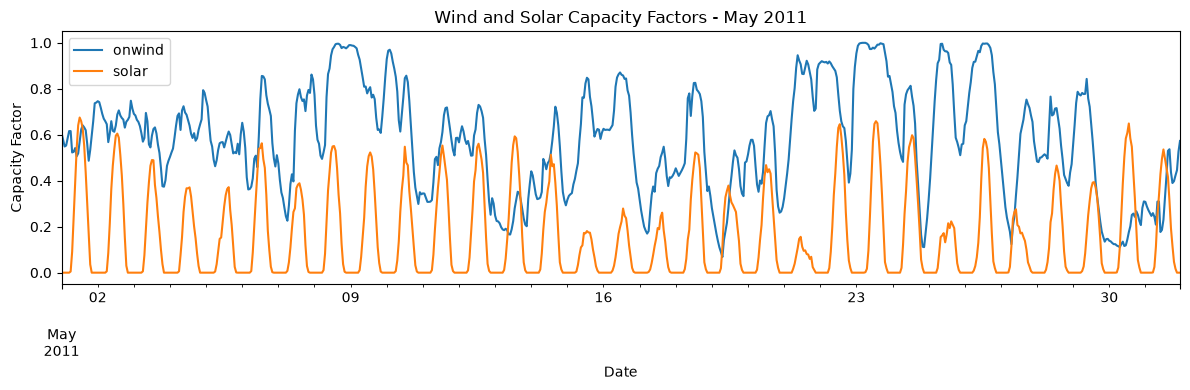

In [159]:
# convert the existing indext to a DatetimeIndex, which allows for time-based indexing and resampling
df.index = pd.to_datetime(df.index)

may_cf = (df
          # select all hourly observations in May 2011
          .loc["2011-05"]
          )

plot = (may_cf
        .plot(figsize=(12, 4),
              title="Wind and Solar Capacity Factors - May 2011",
              xlabel="Date",
              ylabel="Capacity Factor")
        )

# adjust spacing to avoid overlapping labels and titles 
plt.tight_layout()
plt.show()

**Task 5:** Plot the weekly average capacity factors for wind and solar over the entire time period.

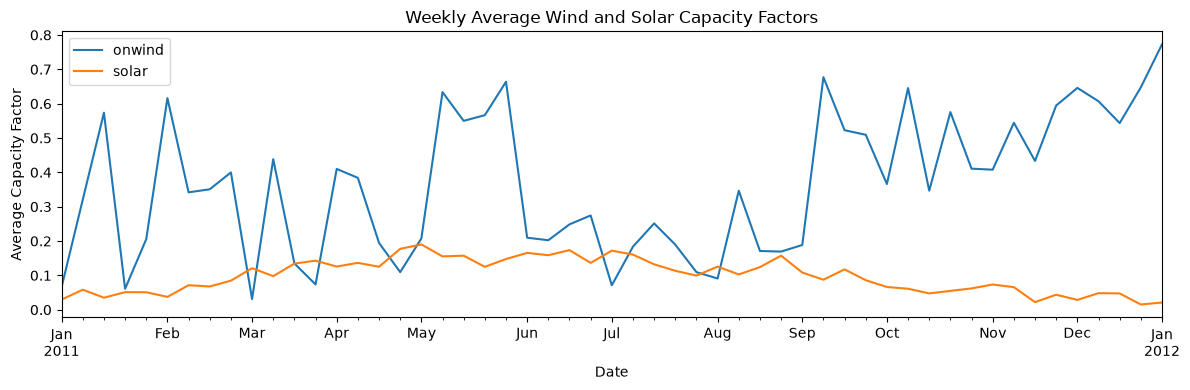

In [ ]:
# calculate weekly average capacity factors
weekly_cf = (df
             # group observations into weeks
             .resample("W") # W: weekly frequency
             # by default, Pandas uses weeks ending on Sunday
             # all observations within each calendar week belong to the same group
             # why .resample() rather than .group()?
             # .groupby(): categories such as tech type
             # .resample("W"): calendar weeks
             # .resample("D"): calendar days
             # .resample("MS"): calendar months
             .mean()
             )

plot = (weekly_cf
        .plot(figsize=(12, 4),
              title="Weekly Average Wind and Solar Capacity Factors",
              xlabel="Date",
              ylabel="Average Capacity Factor")
        )

plt.tight_layout()
plt.show()

**Task 6:** Go to [model.energy](https://model.energy) and retrieve the time series for another region of your choice. Recreate the analysis above and compare the results.

:::{note}
Look for "Download Comma-Separated-Variable (CSV) file of data" in Step 2.
:::